In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("IBM_HR_Analytics_Project") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/09/30 22:33:03 WARN Utils: Your hostname, Srishtis-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.108 instead (on interface en0)
26/09/30 22:33:03 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/30 22:33:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
df = spark.read.csv(
    "/Users/srishtikashyap/Desktop/Pyspark-Practice/Data/data.csv",
    header=True,
    inferSchema=True
)

In [3]:
df.show()

+---+---------+-----------------+---------+--------------------+----------------+---------+--------------+-------------+--------------+-----------------------+------+----------+--------------+--------+--------------------+---------------+-------------+-------------+-----------+------------------+------+--------+-----------------+-----------------+------------------------+-------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+
|Age|Attrition|   BusinessTravel|DailyRate|          Department|DistanceFromHome|Education|EducationField|EmployeeCount|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|             JobRole|JobSatisfaction|MaritalStatus|MonthlyIncome|MonthlyRate|NumCompaniesWorked|Over18|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StandardHours|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalanc

26/09/30 22:33:06 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


In [4]:
print("Rows: ", df.count())
print("Columns: ", len(df.columns))

Rows:  1470
Columns:  35


In [5]:
df.printSchema()

root
 |-- Age: integer (nullable = true)
 |-- Attrition: string (nullable = true)
 |-- BusinessTravel: string (nullable = true)
 |-- DailyRate: integer (nullable = true)
 |-- Department: string (nullable = true)
 |-- DistanceFromHome: integer (nullable = true)
 |-- Education: integer (nullable = true)
 |-- EducationField: string (nullable = true)
 |-- EmployeeCount: integer (nullable = true)
 |-- EmployeeNumber: integer (nullable = true)
 |-- EnvironmentSatisfaction: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- HourlyRate: integer (nullable = true)
 |-- JobInvolvement: integer (nullable = true)
 |-- JobLevel: integer (nullable = true)
 |-- JobRole: string (nullable = true)
 |-- JobSatisfaction: integer (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- MonthlyIncome: integer (nullable = true)
 |-- MonthlyRate: integer (nullable = true)
 |-- NumCompaniesWorked: integer (nullable = true)
 |-- Over18: string (nullable = true)
 |-- OverTime: string 

In [6]:
df.show(10, truncate=False)


+---+---------+-----------------+---------+----------------------+----------------+---------+--------------+-------------+--------------+-----------------------+------+----------+--------------+--------+-------------------------+---------------+-------------+-------------+-----------+------------------+------+--------+-----------------+-----------------+------------------------+-------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+
|Age|Attrition|BusinessTravel   |DailyRate|Department            |DistanceFromHome|Education|EducationField|EmployeeCount|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|JobRole                  |JobSatisfaction|MaritalStatus|MonthlyIncome|MonthlyRate|NumCompaniesWorked|Over18|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StandardHours|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|

In [7]:
df.describe().show()

+-------+------------------+---------+--------------+------------------+---------------+----------------+------------------+----------------+-------------+-----------------+-----------------------+------+------------------+------------------+------------------+--------------------+------------------+-------------+-----------------+------------------+------------------+------+--------+------------------+-------------------+------------------------+-------------+------------------+------------------+---------------------+------------------+------------------+------------------+-----------------------+--------------------+
|summary|               Age|Attrition|BusinessTravel|         DailyRate|     Department|DistanceFromHome|         Education|  EducationField|EmployeeCount|   EmployeeNumber|EnvironmentSatisfaction|Gender|        HourlyRate|    JobInvolvement|          JobLevel|             JobRole|   JobSatisfaction|MaritalStatus|    MonthlyIncome|       MonthlyRate|NumCompaniesWorked|O

In [8]:
print(df.columns)

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [9]:
df.describe().show()

+-------+------------------+---------+--------------+------------------+---------------+----------------+------------------+----------------+-------------+-----------------+-----------------------+------+------------------+------------------+------------------+--------------------+------------------+-------------+-----------------+------------------+------------------+------+--------+------------------+-------------------+------------------------+-------------+------------------+------------------+---------------------+------------------+------------------+------------------+-----------------------+--------------------+
|summary|               Age|Attrition|BusinessTravel|         DailyRate|     Department|DistanceFromHome|         Education|  EducationField|EmployeeCount|   EmployeeNumber|EnvironmentSatisfaction|Gender|        HourlyRate|    JobInvolvement|          JobLevel|             JobRole|   JobSatisfaction|MaritalStatus|    MonthlyIncome|       MonthlyRate|NumCompaniesWorked|O

In [10]:
df.select("Attrition").distinct().show()

df.select("Department").distinct().show()

df.select("BusinessTravel").distinct().show()

df.select("JobRole").distinct().show()

+---------+
|Attrition|
+---------+
|       No|
|      Yes|
+---------+

+--------------------+
|          Department|
+--------------------+
|               Sales|
|Research & Develo...|
|     Human Resources|
+--------------------+

+-----------------+
|   BusinessTravel|
+-----------------+
|Travel_Frequently|
|       Non-Travel|
|    Travel_Rarely|
+-----------------+

+--------------------+
|             JobRole|
+--------------------+
|     Sales Executive|
|Manufacturing Dir...|
|Laboratory Techni...|
|Sales Representative|
|Healthcare Repres...|
|  Research Scientist|
|             Manager|
|   Research Director|
|     Human Resources|
+--------------------+



In [11]:
from pyspark.sql.functions import col, sum

In [12]:
null_counts = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

null_counts.show(truncate=False)

+---+---------+--------------+---------+----------+----------------+---------+--------------+-------------+--------------+-----------------------+------+----------+--------------+--------+-------+---------------+-------------+-------------+-----------+------------------+------+--------+-----------------+-----------------+------------------------+-------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+
|Age|Attrition|BusinessTravel|DailyRate|Department|DistanceFromHome|Education|EducationField|EmployeeCount|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|JobRole|JobSatisfaction|MaritalStatus|MonthlyIncome|MonthlyRate|NumCompaniesWorked|Over18|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StandardHours|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSinceLastPr

In [13]:
df.show()

+---+---------+-----------------+---------+--------------------+----------------+---------+--------------+-------------+--------------+-----------------------+------+----------+--------------+--------+--------------------+---------------+-------------+-------------+-----------+------------------+------+--------+-----------------+-----------------+------------------------+-------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+
|Age|Attrition|   BusinessTravel|DailyRate|          Department|DistanceFromHome|Education|EducationField|EmployeeCount|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|             JobRole|JobSatisfaction|MaritalStatus|MonthlyIncome|MonthlyRate|NumCompaniesWorked|Over18|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StandardHours|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalanc

In [14]:
df.columns

['Age',
 'Attrition',
 'BusinessTravel',
 'DailyRate',
 'Department',
 'DistanceFromHome',
 'Education',
 'EducationField',
 'EmployeeCount',
 'EmployeeNumber',
 'EnvironmentSatisfaction',
 'Gender',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'Over18',
 'OverTime',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StandardHours',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

In [15]:
total_rows = df.count()
distinct_rows = df.distinct().count()

print("Total Rows: ", total_rows)
print("Distinct Rows: ", distinct_rows)
print("Duplicate Rows: ", total_rows - distinct_rows)

Total Rows:  1470
Distinct Rows:  1470
Duplicate Rows:  0


In [16]:
from pyspark.sql.functions import col

duplicate_ids = (
    df.groupBy("EmployeeNumber")
      .count()
      .filter(col("count") > 1)
)

duplicate_ids.show()

+--------------+-----+
|EmployeeNumber|count|
+--------------+-----+
+--------------+-----+



In [17]:
df.groupBy("Attrition").count().show()

+---------+-----+
|Attrition|count|
+---------+-----+
|       No| 1233|
|      Yes|  237|
+---------+-----+



In [18]:
from pyspark.sql.functions import min, max

df.select(
    min("Age").alias("Min_Age"),
    max("Age").alias("Max_Age"),
    min("MonthlyIncome").alias("Min_Income"),
    max("MonthlyIncome").alias("Max_Income"),
    min("YearsAtCompany").alias("Min_Years"),
    max("YearsAtCompany").alias("Max_Years")
).show()

+-------+-------+----------+----------+---------+---------+
|Min_Age|Max_Age|Min_Income|Max_Income|Min_Years|Max_Years|
+-------+-------+----------+----------+---------+---------+
|     18|     60|      1009|     19999|        0|       40|
+-------+-------+----------+----------+---------+---------+



In [19]:
df.filter(
    col("YearsAtCompany") > col("TotalWorkingYears")
).show()

+---+---------+--------------+---------+----------+----------------+---------+--------------+-------------+--------------+-----------------------+------+----------+--------------+--------+-------+---------------+-------------+-------------+-----------+------------------+------+--------+-----------------+-----------------+------------------------+-------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+
|Age|Attrition|BusinessTravel|DailyRate|Department|DistanceFromHome|Education|EducationField|EmployeeCount|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|JobRole|JobSatisfaction|MaritalStatus|MonthlyIncome|MonthlyRate|NumCompaniesWorked|Over18|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StandardHours|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSinceLastPr

In [20]:
df.filter(
    col("YearsInCurrentRole") > col("YearsAtCompany")
).show()


+---+---------+--------------+---------+----------+----------------+---------+--------------+-------------+--------------+-----------------------+------+----------+--------------+--------+-------+---------------+-------------+-------------+-----------+------------------+------+--------+-----------------+-----------------+------------------------+-------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+
|Age|Attrition|BusinessTravel|DailyRate|Department|DistanceFromHome|Education|EducationField|EmployeeCount|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|JobRole|JobSatisfaction|MaritalStatus|MonthlyIncome|MonthlyRate|NumCompaniesWorked|Over18|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StandardHours|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSinceLastPr

In [21]:
df.select("Gender").distinct().show()

df.select("Department").distinct().show()

df.select("BusinessTravel").distinct().show()

+------+
|Gender|
+------+
|Female|
|  Male|
+------+

+--------------------+
|          Department|
+--------------------+
|               Sales|
|Research & Develo...|
|     Human Resources|
+--------------------+

+-----------------+
|   BusinessTravel|
+-----------------+
|Travel_Frequently|
|       Non-Travel|
|    Travel_Rarely|
+-----------------+



In [22]:
df.select(
    "Over18",
    "EmployeeCount",
    "StandardHours"
).distinct().show()

+------+-------------+-------------+
|Over18|EmployeeCount|StandardHours|
+------+-------------+-------------+
|     Y|            1|           80|
+------+-------------+-------------+



In [23]:
df_clean = df.drop("Over18", "EmployeeCount", "StandardHours")

In [24]:
print("Original columns:", len(df.columns))
print("Cleaned columns:", len(df_clean.columns))

Original columns: 35
Cleaned columns: 32


In [25]:
df_clean.printSchema()

root
 |-- Age: integer (nullable = true)
 |-- Attrition: string (nullable = true)
 |-- BusinessTravel: string (nullable = true)
 |-- DailyRate: integer (nullable = true)
 |-- Department: string (nullable = true)
 |-- DistanceFromHome: integer (nullable = true)
 |-- Education: integer (nullable = true)
 |-- EducationField: string (nullable = true)
 |-- EmployeeNumber: integer (nullable = true)
 |-- EnvironmentSatisfaction: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- HourlyRate: integer (nullable = true)
 |-- JobInvolvement: integer (nullable = true)
 |-- JobLevel: integer (nullable = true)
 |-- JobRole: string (nullable = true)
 |-- JobSatisfaction: integer (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- MonthlyIncome: integer (nullable = true)
 |-- MonthlyRate: integer (nullable = true)
 |-- NumCompaniesWorked: integer (nullable = true)
 |-- OverTime: string (nullable = true)
 |-- PercentSalaryHike: integer (nullable = true)
 |-- Performance

In [26]:
df_clean = df_clean.withColumnRenamed(
    "MonthlyIncome",
    "Monthly_Income"
)

In [27]:
df_clean.printSchema()

root
 |-- Age: integer (nullable = true)
 |-- Attrition: string (nullable = true)
 |-- BusinessTravel: string (nullable = true)
 |-- DailyRate: integer (nullable = true)
 |-- Department: string (nullable = true)
 |-- DistanceFromHome: integer (nullable = true)
 |-- Education: integer (nullable = true)
 |-- EducationField: string (nullable = true)
 |-- EmployeeNumber: integer (nullable = true)
 |-- EnvironmentSatisfaction: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- HourlyRate: integer (nullable = true)
 |-- JobInvolvement: integer (nullable = true)
 |-- JobLevel: integer (nullable = true)
 |-- JobRole: string (nullable = true)
 |-- JobSatisfaction: integer (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- Monthly_Income: integer (nullable = true)
 |-- MonthlyRate: integer (nullable = true)
 |-- NumCompaniesWorked: integer (nullable = true)
 |-- OverTime: string (nullable = true)
 |-- PercentSalaryHike: integer (nullable = true)
 |-- Performanc

In [28]:
from pyspark.sql.functions import col, when

df_clean = df_clean.withColumn(
    "Attrition_Flag",
    when(col("Attrition") == "Yes", 1).otherwise(0)
)

In [29]:
df_clean.select("Attrition", "Attrition_Flag").distinct().show()

+---------+--------------+
|Attrition|Attrition_Flag|
+---------+--------------+
|      Yes|             1|
|       No|             0|
+---------+--------------+



In [30]:
df_clean = df_clean.withColumn(
    "Age_group",
    when(col("Age") < 25, "Under 25")
    .when(col("Age") < 35, "25-34")
    .when(col("Age") < 45, "35-44")
    .when(col("Age") < 55, "45-54")
    .otherwise("55+")
         )

In [31]:
df_clean.select("Age_group").distinct().show()

+---------+
|Age_group|
+---------+
|    45-54|
| Under 25|
|    35-44|
|    25-34|
|      55+|
+---------+



In [32]:
df_clean.groupBy("Age_Group").count().orderBy("Age_Group").show()

+---------+-----+
|Age_Group|count|
+---------+-----+
|    25-34|  554|
|    35-44|  505|
|    45-54|  245|
|      55+|   69|
| Under 25|   97|
+---------+-----+



In [33]:
from pyspark.sql.functions import sum

df_clean.groupBy("Age_Group") \
    .count() \
    .agg(sum("count").alias("Total_Employees")) \
    .show()

+---------------+
|Total_Employees|
+---------------+
|           1470|
+---------------+



In [34]:
df_clean.select("*").show()

+---+---------+-----------------+---------+--------------------+----------------+---------+--------------+--------------+-----------------------+------+----------+--------------+--------+--------------------+---------------+-------------+--------------+-----------+------------------+--------+-----------------+-----------------+------------------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+--------------+---------+
|Age|Attrition|   BusinessTravel|DailyRate|          Department|DistanceFromHome|Education|EducationField|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|             JobRole|JobSatisfaction|MaritalStatus|Monthly_Income|MonthlyRate|NumCompaniesWorked|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSi

In [35]:
from pyspark.sql.functions import avg, count, round

age_attrition = df_clean.groupBy("Age_Group").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left"),
    round(avg("Attrition_Flag") * 100, 2).alias("Attrition_Rate")
)

age_attrition.show()

+---------+---------------+--------------+--------------+
|Age_Group|Total_Employees|Employees_Left|Attrition_Rate|
+---------+---------------+--------------+--------------+
|    45-54|            245|            25|          10.2|
| Under 25|             97|            38|         39.18|
|    35-44|            505|            51|          10.1|
|    25-34|            554|           112|         20.22|
|      55+|             69|            11|         15.94|
+---------+---------------+--------------+--------------+



In [36]:
age_attrition.orderBy(
    col("Attrition_Rate").desc()
).show()

+---------+---------------+--------------+--------------+
|Age_Group|Total_Employees|Employees_Left|Attrition_Rate|
+---------+---------------+--------------+--------------+
| Under 25|             97|            38|         39.18|
|    25-34|            554|           112|         20.22|
|      55+|             69|            11|         15.94|
|    45-54|            245|            25|          10.2|
|    35-44|            505|            51|          10.1|
+---------+---------------+--------------+--------------+



In [37]:
department_attrition = df_clean.groupBy("Department").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left"),
    round(avg("Attrition_Flag") * 100, 2).alias("Attrition_Rate")
)

department_attrition.show()

+--------------------+---------------+--------------+--------------+
|          Department|Total_Employees|Employees_Left|Attrition_Rate|
+--------------------+---------------+--------------+--------------+
|               Sales|            446|            92|         20.63|
|Research & Develo...|            961|           133|         13.84|
|     Human Resources|             63|            12|         19.05|
+--------------------+---------------+--------------+--------------+



In [38]:
department_attrition.orderBy(
    col("Attrition_Rate").desc()
).show()

+--------------------+---------------+--------------+--------------+
|          Department|Total_Employees|Employees_Left|Attrition_Rate|
+--------------------+---------------+--------------+--------------+
|               Sales|            446|            92|         20.63|
|     Human Resources|             63|            12|         19.05|
|Research & Develo...|            961|           133|         13.84|
+--------------------+---------------+--------------+--------------+



In [39]:
jobrole_attrition = df_clean.groupBy("JobRole").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left"),
    round(avg("Attrition_Flag") * 100, 2).alias("Attrition_Rate")
)

jobrole_attrition.show()

+--------------------+---------------+--------------+--------------+
|             JobRole|Total_Employees|Employees_Left|Attrition_Rate|
+--------------------+---------------+--------------+--------------+
|     Sales Executive|            326|            57|         17.48|
|Manufacturing Dir...|            145|            10|           6.9|
|Laboratory Techni...|            259|            62|         23.94|
|Sales Representative|             83|            33|         39.76|
|Healthcare Repres...|            131|             9|          6.87|
|  Research Scientist|            292|            47|          16.1|
|             Manager|            102|             5|           4.9|
|   Research Director|             80|             2|           2.5|
|     Human Resources|             52|            12|         23.08|
+--------------------+---------------+--------------+--------------+



In [40]:
jobrole_attrition.orderBy(
    col("Attrition_Rate").desc()
).show()

+--------------------+---------------+--------------+--------------+
|             JobRole|Total_Employees|Employees_Left|Attrition_Rate|
+--------------------+---------------+--------------+--------------+
|Sales Representative|             83|            33|         39.76|
|Laboratory Techni...|            259|            62|         23.94|
|     Human Resources|             52|            12|         23.08|
|     Sales Executive|            326|            57|         17.48|
|  Research Scientist|            292|            47|          16.1|
|Manufacturing Dir...|            145|            10|           6.9|
|Healthcare Repres...|            131|             9|          6.87|
|             Manager|            102|             5|           4.9|
|   Research Director|             80|             2|           2.5|
+--------------------+---------------+--------------+--------------+



In [41]:
department_job_attrition = df_clean.groupBy(
    "Department",
    "JobRole"
).agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left"),
    round(
        avg("Attrition_Flag") * 100, 2
    ).alias("Attrition_Rate")
)

department_job_attrition.show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|
+----------------------+-------------------------+---------------+--------------+--------------+
|Sales                 |Sales Representative     |83             |33            |39.76         |
|Research & Development|Research Director        |80             |2             |2.5           |
|Human Resources       |Human Resources          |52             |12            |23.08         |
|Sales                 |Sales Executive          |326            |57            |17.48         |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |
|Research & Development|Manager                  |54             |3             |5.56          |
|Human Resources       |Manager                  |11             |0             |0.0           |
|Research & Development|Health

In [42]:
department_job_attrition.orderBy(
    col("Attrition_Rate").desc()
).show()

+--------------------+--------------------+---------------+--------------+--------------+
|          Department|             JobRole|Total_Employees|Employees_Left|Attrition_Rate|
+--------------------+--------------------+---------------+--------------+--------------+
|               Sales|Sales Representative|             83|            33|         39.76|
|Research & Develo...|Laboratory Techni...|            259|            62|         23.94|
|     Human Resources|     Human Resources|             52|            12|         23.08|
|               Sales|     Sales Executive|            326|            57|         17.48|
|Research & Develo...|  Research Scientist|            292|            47|          16.1|
|Research & Develo...|Manufacturing Dir...|            145|            10|           6.9|
|Research & Develo...|Healthcare Repres...|            131|             9|          6.87|
|Research & Develo...|             Manager|             54|             3|          5.56|
|         

In [43]:
from pyspark.sql.window import Window
from pyspark.sql.functions import avg, col

dept_window = Window.partitionBy("Department")

comparison = department_job_attrition.withColumn(
    "Dept_Avg_Attrition",
    avg("Attrition_Rate").over(dept_window)
)
comparison.show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+------------------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Dept_Avg_Attrition|
+----------------------+-------------------------+---------------+--------------+--------------+------------------+
|Human Resources       |Human Resources          |52             |12            |23.08         |11.54             |
|Human Resources       |Manager                  |11             |0             |0.0           |11.54             |
|Research & Development|Research Director        |80             |2             |2.5           |10.311666666666667|
|Research & Development|Manufacturing Director   |145            |10            |6.9           |10.311666666666667|
|Research & Development|Manager                  |54             |3             |5.56          |10.311666666666667|
|Research & Development|Healthcare Representative|131            |9     

In [44]:
department_summary = df_clean.groupBy("Department").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

department_summary = department_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

department_summary.show()

+--------------------+---------------+--------------+--------------+
|          Department|Total_Employees|Employees_Left|Attrition_Rate|
+--------------------+---------------+--------------+--------------+
|               Sales|            446|            92|         20.63|
|Research & Develo...|            961|           133|         13.84|
|     Human Resources|             63|            12|         19.05|
+--------------------+---------------+--------------+--------------+



In [45]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number, col

rank_window = Window.partitionBy("Department").orderBy(
    col("Attrition_Rate").desc()
)

In [46]:
ranked_jobs = department_job_attrition.withColumn(
    "Rank",
    row_number().over(rank_window)
)

ranked_jobs.orderBy(
    "Department", "Rank"
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+----+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Rank|
+----------------------+-------------------------+---------------+--------------+--------------+----+
|Human Resources       |Human Resources          |52             |12            |23.08         |1   |
|Human Resources       |Manager                  |11             |0             |0.0           |2   |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |1   |
|Research & Development|Research Scientist       |292            |47            |16.1          |2   |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |3   |
|Research & Development|Healthcare Representative|131            |9             |6.87          |4   |
|Research & Development|Manager                  |54             |3             |5

In [47]:
from pyspark.sql.window import Window
from pyspark.sql.functions import rank, dense_rank, col

rank_window = Window.partitionBy("Department").orderBy(
    col("Attrition_Rate").desc()
)

In [48]:
ranked_jobs = department_job_attrition \
    .withColumn("Row_Number", row_number().over(rank_window)) \
    .withColumn("Rank", rank().over(rank_window)) \
    .withColumn("Dense_Rank", dense_rank().over(rank_window))

ranked_jobs.orderBy(
    "Department", "Rank"
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+----------+----+----------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Row_Number|Rank|Dense_Rank|
+----------------------+-------------------------+---------------+--------------+--------------+----------+----+----------+
|Human Resources       |Human Resources          |52             |12            |23.08         |1         |1   |1         |
|Human Resources       |Manager                  |11             |0             |0.0           |2         |2   |2         |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |1         |1   |1         |
|Research & Development|Research Scientist       |292            |47            |16.1          |2         |2   |2         |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |3         |3   |3         |
|Researc

In [49]:
from pyspark.sql.window import Window
from pyspark.sql.functions import lag, lead, col

comparison_window = Window.partitionBy("Department").orderBy(
    col("Attrition_Rate").desc()
)

In [50]:
job_comparison = department_job_attrition \
    .withColumn(
        "Previous_Rate",
        lag("Attrition_Rate").over(comparison_window)
    ) \
    .withColumn(
        "Next_Rate",
        lead("Attrition_Rate").over(comparison_window)
    )

job_comparison.orderBy(
    "Department", col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Previous_Rate|Next_Rate|
+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+
|Human Resources       |Human Resources          |52             |12            |23.08         |NULL         |0.0      |
|Human Resources       |Manager                  |11             |0             |0.0           |23.08        |NULL     |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |NULL         |16.1     |
|Research & Development|Research Scientist       |292            |47            |16.1          |23.94        |6.9      |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |16.1         |6.87     |
|Research & Development|Healthca

In [51]:
job_comparison = job_comparison.withColumn(
    "Rate_Difference",
    col("Attrition_Rate") - col("Previous_Rate")
)

job_comparison.orderBy(
    "Department",
    col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+--------------------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Previous_Rate|Next_Rate|Rate_Difference     |
+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+--------------------+
|Human Resources       |Human Resources          |52             |12            |23.08         |NULL         |0.0      |NULL                |
|Human Resources       |Manager                  |11             |0             |0.0           |23.08        |NULL     |-23.08              |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |NULL         |16.1     |NULL                |
|Research & Development|Research Scientist       |292            |47            |16.1          |23.94        |6.9      |-7.84               |
|Resea

In [52]:
print("Original rows:", df.count())
print("Cleaned rows:", df_clean.count())

print("Original columns:", len(df.columns))
print("Cleaned columns:", len(df_clean.columns))

Original rows: 1470
Cleaned rows: 1470
Original columns: 35
Cleaned columns: 34


In [53]:
from pyspark.sql.functions import col, sum as spark_sum

df_clean.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in df_clean.columns
]).show()

+---+---------+--------------+---------+----------+----------------+---------+--------------+--------------+-----------------------+------+----------+--------------+--------+-------+---------------+-------------+--------------+-----------+------------------+--------+-----------------+-----------------+------------------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+--------------+---------+
|Age|Attrition|BusinessTravel|DailyRate|Department|DistanceFromHome|Education|EducationField|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|JobRole|JobSatisfaction|MaritalStatus|Monthly_Income|MonthlyRate|NumCompaniesWorked|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSinceLastPromotion|YearsWithCurrManager|Attrition_Flag

In [54]:
df_clean.select(
    "Age",
    "Age_Group",
    "Attrition",
    "Attrition_Flag"
).show(10)

+---+---------+---------+--------------+
|Age|Age_Group|Attrition|Attrition_Flag|
+---+---------+---------+--------------+
| 41|    35-44|      Yes|             1|
| 49|    45-54|       No|             0|
| 37|    35-44|      Yes|             1|
| 33|    25-34|       No|             0|
| 27|    25-34|       No|             0|
| 32|    25-34|       No|             0|
| 59|      55+|       No|             0|
| 30|    25-34|       No|             0|
| 38|    35-44|       No|             0|
| 36|    35-44|       No|             0|
+---+---------+---------+--------------+
only showing top 10 rows


In [55]:
df_clean.write \
    .mode("overwrite") \
    .parquet("/Users/srishtikashyap/Desktop/Pyspark-Practice/Data/processed/hr_cleaned")



In [56]:
df_parquet = spark.read.parquet(
    "/Users/srishtikashyap/Desktop/Pyspark-Practice/Data/processed/hr_cleaned"
)

df_parquet.show(5)

+---+---------+-----------------+---------+--------------------+----------------+---------+--------------+--------------+-----------------------+------+----------+--------------+--------+--------------------+---------------+-------------+--------------+-----------+------------------+--------+-----------------+-----------------+------------------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+--------------+---------+
|Age|Attrition|   BusinessTravel|DailyRate|          Department|DistanceFromHome|Education|EducationField|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|             JobRole|JobSatisfaction|MaritalStatus|Monthly_Income|MonthlyRate|NumCompaniesWorked|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSi

In [57]:
print("Rows:", df_parquet.count())
df_parquet.printSchema()

Rows: 1470
root
 |-- Age: integer (nullable = true)
 |-- Attrition: string (nullable = true)
 |-- BusinessTravel: string (nullable = true)
 |-- DailyRate: integer (nullable = true)
 |-- Department: string (nullable = true)
 |-- DistanceFromHome: integer (nullable = true)
 |-- Education: integer (nullable = true)
 |-- EducationField: string (nullable = true)
 |-- EmployeeNumber: integer (nullable = true)
 |-- EnvironmentSatisfaction: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- HourlyRate: integer (nullable = true)
 |-- JobInvolvement: integer (nullable = true)
 |-- JobLevel: integer (nullable = true)
 |-- JobRole: string (nullable = true)
 |-- JobSatisfaction: integer (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- Monthly_Income: integer (nullable = true)
 |-- MonthlyRate: integer (nullable = true)
 |-- NumCompaniesWorked: integer (nullable = true)
 |-- OverTime: string (nullable = true)
 |-- PercentSalaryHike: integer (nullable = true)
 |--

In [58]:
df_clean.write \
    .mode("overwrite") \
    .partitionBy("Department") \
    .parquet("../Data/processed/hr_partitioned")

In [59]:
df_partitioned = spark.read.parquet(
    "../Data/processed/hr_partitioned"
)

df_partitioned.show(5)

+---+---------+-----------------+---------+----------------+---------+--------------+--------------+-----------------------+------+----------+--------------+--------+--------------------+---------------+-------------+--------------+-----------+------------------+--------+-----------------+-----------------+------------------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+--------------+---------+--------------------+
|Age|Attrition|   BusinessTravel|DailyRate|DistanceFromHome|Education|EducationField|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|             JobRole|JobSatisfaction|MaritalStatus|Monthly_Income|MonthlyRate|NumCompaniesWorked|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSinceLastPromotion|Year

In [60]:
df_partitioned.filter(
    col("Department") == "Sales"
).show()

+---+---------+-----------------+---------+----------------+---------+----------------+--------------+-----------------------+------+----------+--------------+--------+--------------------+---------------+-------------+--------------+-----------+------------------+--------+-----------------+-----------------+------------------------+----------------+-----------------+---------------------+---------------+--------------+------------------+-----------------------+--------------------+--------------+---------+----------+
|Age|Attrition|   BusinessTravel|DailyRate|DistanceFromHome|Education|  EducationField|EmployeeNumber|EnvironmentSatisfaction|Gender|HourlyRate|JobInvolvement|JobLevel|             JobRole|JobSatisfaction|MaritalStatus|Monthly_Income|MonthlyRate|NumCompaniesWorked|OverTime|PercentSalaryHike|PerformanceRating|RelationshipSatisfaction|StockOptionLevel|TotalWorkingYears|TrainingTimesLastYear|WorkLifeBalance|YearsAtCompany|YearsInCurrentRole|YearsSinceLastPromotion|YearsWithC

In [61]:
from pyspark.sql.functions import sum, count, round, col

attrition_summary = df_clean.agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

attrition_summary = attrition_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

attrition_summary.show()

+---------------+--------------+--------------+
|Total_Employees|Employees_Left|Attrition_Rate|
+---------------+--------------+--------------+
|           1470|           237|         16.12|
+---------------+--------------+--------------+



In [62]:
from pyspark.sql.functions import count, sum, round, col

department_summary = df_clean.groupBy("Department").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

department_summary = department_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

department_summary.orderBy(
    col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+---------------+--------------+--------------+
|Department            |Total_Employees|Employees_Left|Attrition_Rate|
+----------------------+---------------+--------------+--------------+
|Sales                 |446            |92            |20.63         |
|Human Resources       |63             |12            |19.05         |
|Research & Development|961            |133           |13.84         |
+----------------------+---------------+--------------+--------------+



In [63]:
jobrole_summary = df_clean.groupBy("JobRole").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

jobrole_summary = jobrole_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

jobrole_summary.orderBy(
    col("Attrition_Rate").desc()
).show(truncate=False)

+-------------------------+---------------+--------------+--------------+
|JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|
+-------------------------+---------------+--------------+--------------+
|Sales Representative     |83             |33            |39.76         |
|Laboratory Technician    |259            |62            |23.94         |
|Human Resources          |52             |12            |23.08         |
|Sales Executive          |326            |57            |17.48         |
|Research Scientist       |292            |47            |16.1          |
|Manufacturing Director   |145            |10            |6.9           |
|Healthcare Representative|131            |9             |6.87          |
|Manager                  |102            |5             |4.9           |
|Research Director        |80             |2             |2.5           |
+-------------------------+---------------+--------------+--------------+



In [64]:
age_summary = df_clean.groupBy("Age_Group").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

age_summary = age_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

age_summary.orderBy("Age_Group").show()

+---------+---------------+--------------+--------------+
|Age_Group|Total_Employees|Employees_Left|Attrition_Rate|
+---------+---------------+--------------+--------------+
|    25-34|            554|           112|         20.22|
|    35-44|            505|            51|          10.1|
|    45-54|            245|            25|          10.2|
|      55+|             69|            11|         15.94|
| Under 25|             97|            38|         39.18|
+---------+---------------+--------------+--------------+



In [65]:
from pyspark.sql.functions import when, col

df_clean = df_clean.withColumn(
    "Income_Group",
    when(col("Monthly_Income") < 3000, "Low")
    .when(col("Monthly_Income") < 7000, "Medium")
    .otherwise("High")
)

In [66]:
income_summary = df_clean.groupBy("Income_Group").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

income_summary = income_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

income_summary.orderBy("Income_Group").show()

+------------+---------------+--------------+--------------+
|Income_Group|Total_Employees|Employees_Left|Attrition_Rate|
+------------+---------------+--------------+--------------+
|        High|            435|            47|          10.8|
|         Low|            395|           113|         28.61|
|      Medium|            640|            77|         12.03|
+------------+---------------+--------------+--------------+



In [67]:
tenure_summary = df_clean.groupBy("YearsAtCompany").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

tenure_summary = tenure_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

tenure_summary.orderBy("YearsAtCompany").show(50)

+--------------+---------------+--------------+--------------+
|YearsAtCompany|Total_Employees|Employees_Left|Attrition_Rate|
+--------------+---------------+--------------+--------------+
|             0|             44|            16|         36.36|
|             1|            171|            59|          34.5|
|             2|            127|            27|         21.26|
|             3|            128|            20|         15.63|
|             4|            110|            19|         17.27|
|             5|            196|            21|         10.71|
|             6|             76|             9|         11.84|
|             7|             90|            11|         12.22|
|             8|             80|             9|         11.25|
|             9|             82|             8|          9.76|
|            10|            120|            18|          15.0|
|            11|             32|             2|          6.25|
|            12|             14|             0|        

In [68]:
travel_summary = df_clean.groupBy("BusinessTravel").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

travel_summary = travel_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

travel_summary.orderBy(
    col("Attrition_Rate").desc()
).show(truncate=False)

+-----------------+---------------+--------------+--------------+
|BusinessTravel   |Total_Employees|Employees_Left|Attrition_Rate|
+-----------------+---------------+--------------+--------------+
|Travel_Frequently|277            |69            |24.91         |
|Travel_Rarely    |1043           |156           |14.96         |
|Non-Travel       |150            |12            |8.0           |
+-----------------+---------------+--------------+--------------+



In [69]:
overtime_summary = df_clean.groupBy("OverTime").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

overtime_summary = overtime_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

overtime_summary.show()

+--------+---------------+--------------+--------------+
|OverTime|Total_Employees|Employees_Left|Attrition_Rate|
+--------+---------------+--------------+--------------+
|      No|           1054|           110|         10.44|
|     Yes|            416|           127|         30.53|
+--------+---------------+--------------+--------------+



In [70]:
satisfaction_summary = df_clean.groupBy("JobSatisfaction").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

satisfaction_summary = satisfaction_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

satisfaction_summary.orderBy("JobSatisfaction").show()

+---------------+---------------+--------------+--------------+
|JobSatisfaction|Total_Employees|Employees_Left|Attrition_Rate|
+---------------+---------------+--------------+--------------+
|              1|            289|            66|         22.84|
|              2|            280|            46|         16.43|
|              3|            442|            73|         16.52|
|              4|            459|            52|         11.33|
+---------------+---------------+--------------+--------------+



In [71]:
marital_summary = df_clean.groupby("MaritalStatus").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

marital_summary = marital_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

marital_summary.orderBy(
    col("Attrition_Rate").desc()
).show()

+-------------+---------------+--------------+--------------+
|MaritalStatus|Total_Employees|Employees_Left|Attrition_Rate|
+-------------+---------------+--------------+--------------+
|       Single|            470|           120|         25.53|
|      Married|            673|            84|         12.48|
|     Divorced|            327|            33|         10.09|
+-------------+---------------+--------------+--------------+



In [72]:
gender_summary = df_clean.groupby("Gender").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

gender_summary = gender_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)


gender_summary.orderBy(
    col("Attrition_Rate").desc()
).show()

+------+---------------+--------------+--------------+
|Gender|Total_Employees|Employees_Left|Attrition_Rate|
+------+---------------+--------------+--------------+
|  Male|            882|           150|         17.01|
|Female|            588|            87|          14.8|
+------+---------------+--------------+--------------+



In [73]:
joblevel_summary = df_clean.groupBy("JobLevel").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

joblevel_summary = joblevel_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

joblevel_summary.orderBy("JobLevel").show()

+--------+---------------+--------------+--------------+
|JobLevel|Total_Employees|Employees_Left|Attrition_Rate|
+--------+---------------+--------------+--------------+
|       1|            543|           143|         26.34|
|       2|            534|            52|          9.74|
|       3|            218|            32|         14.68|
|       4|            106|             5|          4.72|
|       5|             69|             5|          7.25|
+--------+---------------+--------------+--------------+



In [74]:
role_tenure_summary = df_clean.groupBy("YearsInCurrentRole").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

role_tenure_summary = role_tenure_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

role_tenure_summary.orderBy("YearsInCurrentRole").show(50)

+------------------+---------------+--------------+--------------+
|YearsInCurrentRole|Total_Employees|Employees_Left|Attrition_Rate|
+------------------+---------------+--------------+--------------+
|                 0|            244|            73|         29.92|
|                 1|             57|            11|          19.3|
|                 2|            372|            68|         18.28|
|                 3|            135|            16|         11.85|
|                 4|            104|            15|         14.42|
|                 5|             36|             1|          2.78|
|                 6|             37|             2|          5.41|
|                 7|            222|            31|         13.96|
|                 8|             89|             7|          7.87|
|                 9|             67|             6|          8.96|
|                10|             29|             2|           6.9|
|                11|             22|             0|           

In [75]:
distance_summary = df_clean.groupBy("DistanceFromHome").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

distance_summary = distance_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

distance_summary.orderBy("DistanceFromHome").show(50)

+----------------+---------------+--------------+--------------+
|DistanceFromHome|Total_Employees|Employees_Left|Attrition_Rate|
+----------------+---------------+--------------+--------------+
|               1|            208|            26|          12.5|
|               2|            211|            28|         13.27|
|               3|             84|            14|         16.67|
|               4|             64|             9|         14.06|
|               5|             65|            10|         15.38|
|               6|             59|             7|         11.86|
|               7|             84|            11|          13.1|
|               8|             80|            10|          12.5|
|               9|             85|            18|         21.18|
|              10|             86|            11|         12.79|
|              11|             29|             4|         13.79|
|              12|             20|             6|          30.0|
|              13|       

In [76]:
worklife_summary = df_clean.groupBy("WorkLifeBalance").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

worklife_summary = worklife_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

worklife_summary.orderBy("WorkLifeBalance").show()

+---------------+---------------+--------------+--------------+
|WorkLifeBalance|Total_Employees|Employees_Left|Attrition_Rate|
+---------------+---------------+--------------+--------------+
|              1|             80|            25|         31.25|
|              2|            344|            58|         16.86|
|              3|            893|           127|         14.22|
|              4|            153|            27|         17.65|
+---------------+---------------+--------------+--------------+



In [77]:
performance_summary = df_clean.groupBy("PerformanceRating").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

performance_summary = performance_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

performance_summary.orderBy("PerformanceRating").show()

+-----------------+---------------+--------------+--------------+
|PerformanceRating|Total_Employees|Employees_Left|Attrition_Rate|
+-----------------+---------------+--------------+--------------+
|                3|           1244|           200|         16.08|
|                4|            226|            37|         16.37|
+-----------------+---------------+--------------+--------------+



In [78]:
department_job_summary = df_clean.groupBy(
    "Department", "JobRole"
).agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

department_job_summary = department_job_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

department_job_summary.orderBy(
    "Department", col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|
+----------------------+-------------------------+---------------+--------------+--------------+
|Human Resources       |Human Resources          |52             |12            |23.08         |
|Human Resources       |Manager                  |11             |0             |0.0           |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |
|Research & Development|Research Scientist       |292            |47            |16.1          |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |
|Research & Development|Healthcare Representative|131            |9             |6.87          |
|Research & Development|Manager                  |54             |3             |5.56          |
|Research & Development|Resear

In [79]:
from pyspark.sql.window import Window
from pyspark.sql.functions import avg, round, col

dept_window = Window.partitionBy("Department")

comparison = department_job_summary.withColumn(
    "Dept_Avg_Attrition",
    round(avg("Attrition_Rate").over(dept_window), 2)
)

comparison.select(
    "Department",
    "JobRole",
    "Attrition_Rate",
    "Dept_Avg_Attrition"
).orderBy("Department", "JobRole").show(truncate=False)

+----------------------+-------------------------+--------------+------------------+
|Department            |JobRole                  |Attrition_Rate|Dept_Avg_Attrition|
+----------------------+-------------------------+--------------+------------------+
|Human Resources       |Human Resources          |23.08         |11.54             |
|Human Resources       |Manager                  |0.0           |11.54             |
|Research & Development|Healthcare Representative|6.87          |10.31             |
|Research & Development|Laboratory Technician    |23.94         |10.31             |
|Research & Development|Manager                  |5.56          |10.31             |
|Research & Development|Manufacturing Director   |6.9           |10.31             |
|Research & Development|Research Director        |2.5           |10.31             |
|Research & Development|Research Scientist       |16.1          |10.31             |
|Sales                 |Manager                  |5.41          |

In [80]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number, rank, dense_rank, col

rank_window = Window.partitionBy("Department").orderBy(
    col("Attrition_Rate").desc()
)

ranked_jobs = department_job_summary \
    .withColumn("Row_Number", row_number().over(rank_window)) \
    .withColumn("Rank", rank().over(rank_window)) \
    .withColumn("Dense_Rank", dense_rank().over(rank_window))

ranked_jobs.orderBy("Department", "Rank").show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+----------+----+----------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Row_Number|Rank|Dense_Rank|
+----------------------+-------------------------+---------------+--------------+--------------+----------+----+----------+
|Human Resources       |Human Resources          |52             |12            |23.08         |1         |1   |1         |
|Human Resources       |Manager                  |11             |0             |0.0           |2         |2   |2         |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |1         |1   |1         |
|Research & Development|Research Scientist       |292            |47            |16.1          |2         |2   |2         |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |3         |3   |3         |
|Researc

In [81]:
from pyspark.sql.window import Window
from pyspark.sql.functions import lag, lead, col

comparison_window = Window.partitionBy("Department").orderBy(
    col("Attrition_Rate").desc()
)

job_comparison = department_job_summary \
    .withColumn(
        "Previous_Rate",
        lag("Attrition_Rate").over(comparison_window)
    ) \
    .withColumn(
        "Next_Rate",
        lead("Attrition_Rate").over(comparison_window)
    )

job_comparison.orderBy(
    "Department",
    col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Previous_Rate|Next_Rate|
+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+
|Human Resources       |Human Resources          |52             |12            |23.08         |NULL         |0.0      |
|Human Resources       |Manager                  |11             |0             |0.0           |23.08        |NULL     |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |NULL         |16.1     |
|Research & Development|Research Scientist       |292            |47            |16.1          |23.94        |6.9      |
|Research & Development|Manufacturing Director   |145            |10            |6.9           |16.1         |6.87     |
|Research & Development|Healthca

In [82]:
job_comparison = job_comparison.withColumn(
    "Rate_Difference",
    round(
        col("Attrition_Rate") - col("Previous_Rate"),
        2
    )
)

job_comparison.orderBy(
    "Department",
    col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+---------------+
|Department            |JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|Previous_Rate|Next_Rate|Rate_Difference|
+----------------------+-------------------------+---------------+--------------+--------------+-------------+---------+---------------+
|Human Resources       |Human Resources          |52             |12            |23.08         |NULL         |0.0      |NULL           |
|Human Resources       |Manager                  |11             |0             |0.0           |23.08        |NULL     |-23.08         |
|Research & Development|Laboratory Technician    |259            |62            |23.94         |NULL         |16.1     |NULL           |
|Research & Development|Research Scientist       |292            |47            |16.1          |23.94        |6.9      |-7.84          |
|Research & Development|Manufacturing Dir

In [83]:
department_pd = department_summary.toPandas()

department_pd

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,Department,Total_Employees,Employees_Left,Attrition_Rate
0,Sales,446,92,20.63
1,Research & Development,961,133,13.84
2,Human Resources,63,12,19.05


In [84]:
import pandas as pd
print(pd.__version__)

2.3.3


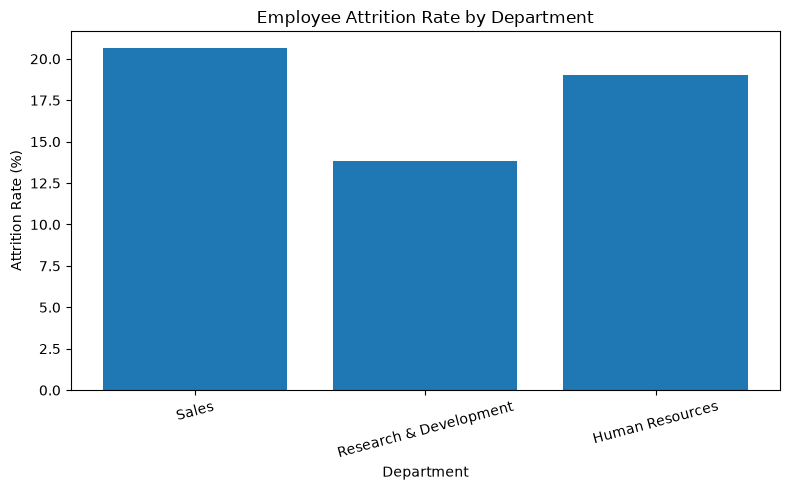

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    department_pd["Department"],
    department_pd["Attrition_Rate"]
)

plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.title("Employee Attrition Rate by Department")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    age_pd["Age_Group"],
    age_pd["Attrition_Rate"]
)

plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Age Group")

plt.tight_layout()
plt.show()

NameError: name 'age_pd' is not defined

<Figure size 800x500 with 0 Axes>

In [87]:
age_pd = age_summary.toPandas()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


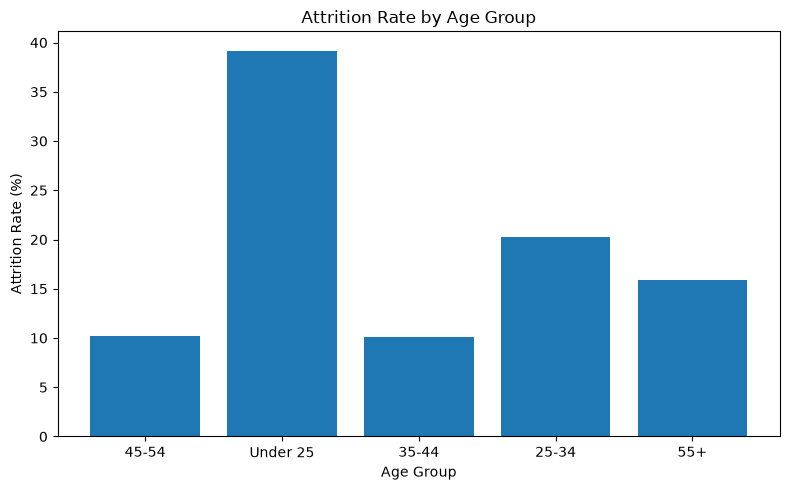

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    age_pd["Age_Group"],
    age_pd["Attrition_Rate"]
)

plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Age Group")

plt.tight_layout()
plt.show()

In [89]:
jobrole_pd = jobrole_summary.toPandas()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


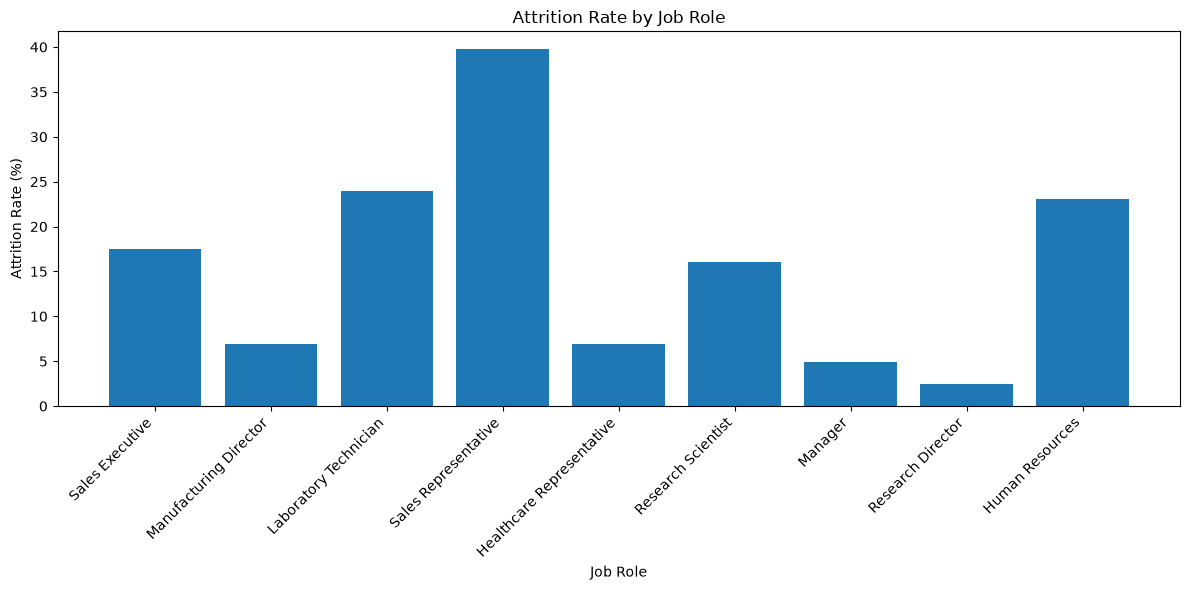

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    jobrole_pd["JobRole"],
    jobrole_pd["Attrition_Rate"]
)

plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Job Role")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [91]:
income_pd = income_summary.toPandas()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


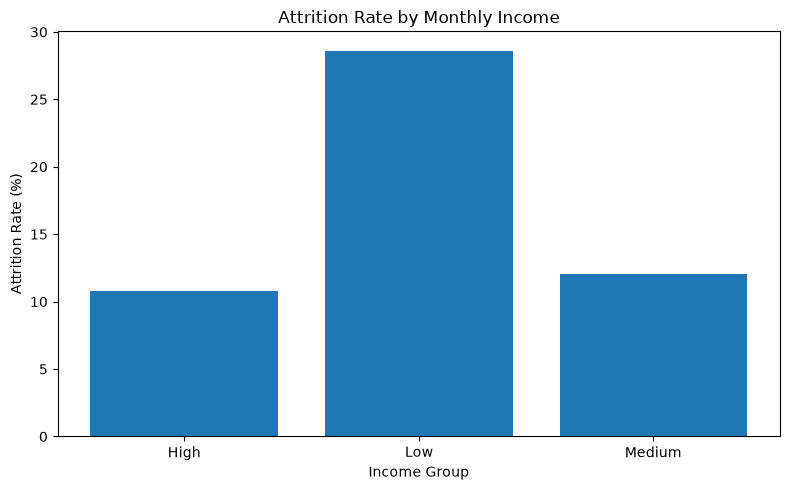

In [92]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    income_pd["Income_Group"],
    income_pd["Attrition_Rate"]
)

plt.xlabel("Income Group")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Monthly Income")

plt.tight_layout()
plt.show()

In [93]:

tenure_pd = tenure_summary.toPandas()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


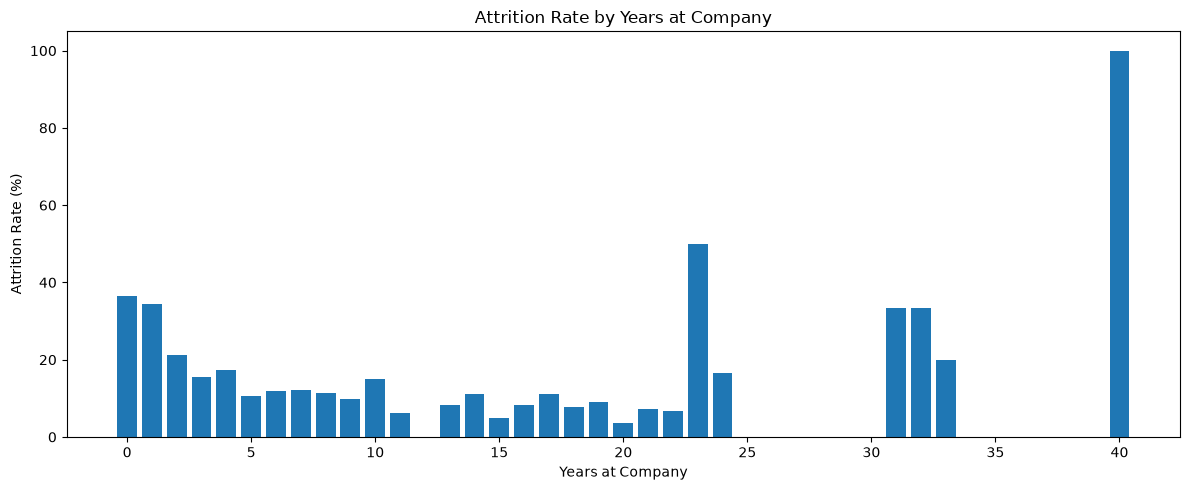

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    tenure_pd["YearsAtCompany"],
    tenure_pd["Attrition_Rate"]
)

plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Years at Company")

plt.tight_layout()
plt.show()

In [95]:
overtime_pd = overtime_summary.toPandas()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


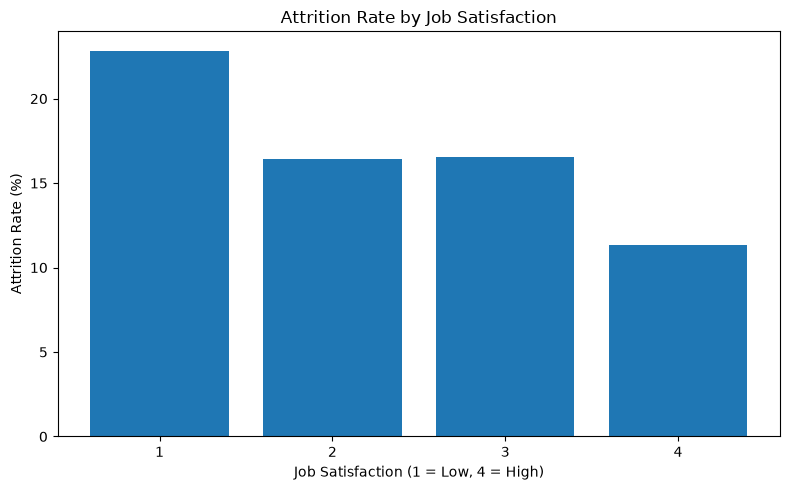

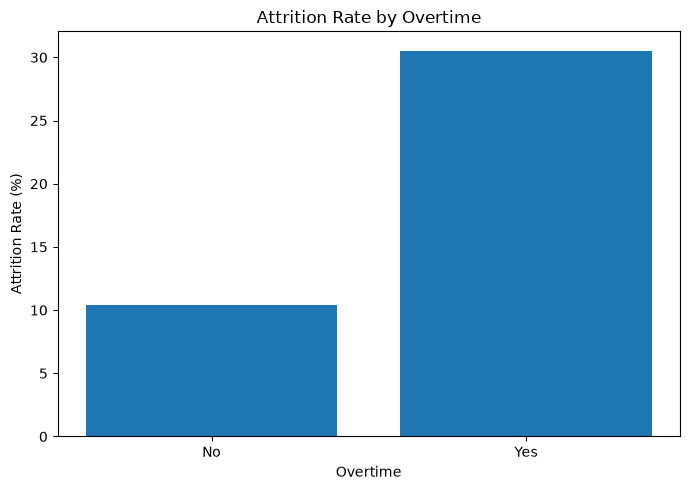

In [99]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    satisfaction_pd["JobSatisfaction"],
    satisfaction_pd["Attrition_Rate"]
)

plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Job Satisfaction")

plt.xticks([1, 2, 3, 4])
plt.tight_layout()
plt.show()
plt.figure(figsize=(7, 5))

plt.bar(
    overtime_pd["OverTime"],
    overtime_pd["Attrition_Rate"]
)

plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Overtime")

plt.tight_layout()
plt.show()

In [97]:
satisfaction_pd = satisfaction_summary.toPandas()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


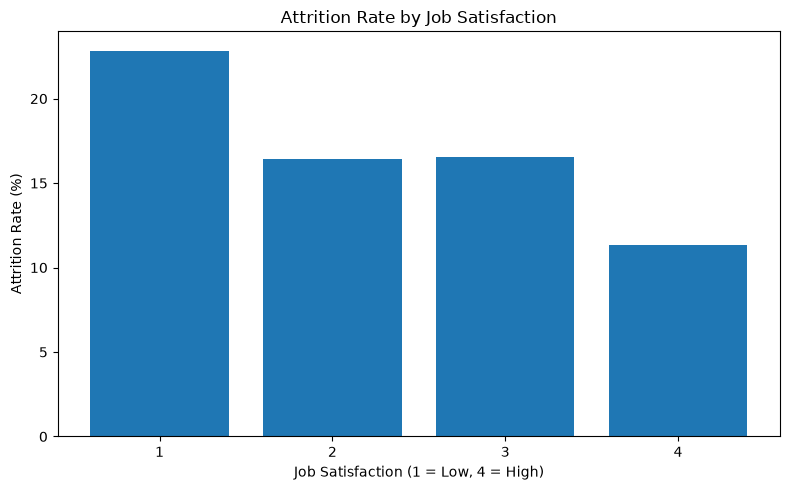

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    satisfaction_pd["JobSatisfaction"],
    satisfaction_pd["Attrition_Rate"]
)

plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Job Satisfaction")

plt.xticks([1, 2, 3, 4])
plt.tight_layout()
plt.show()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


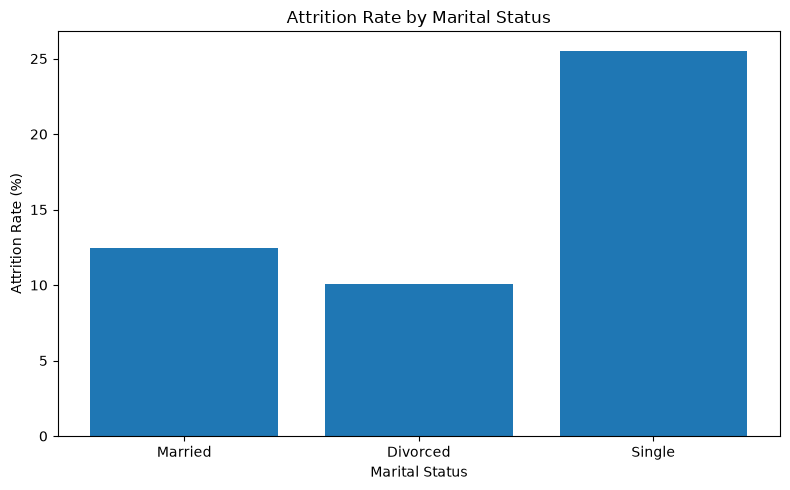

In [101]:
marital_pd = marital_summary.toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    marital_pd["MaritalStatus"],
    marital_pd["Attrition_Rate"]
)

plt.xlabel("Marital Status")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Marital Status")

plt.tight_layout()
plt.show()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


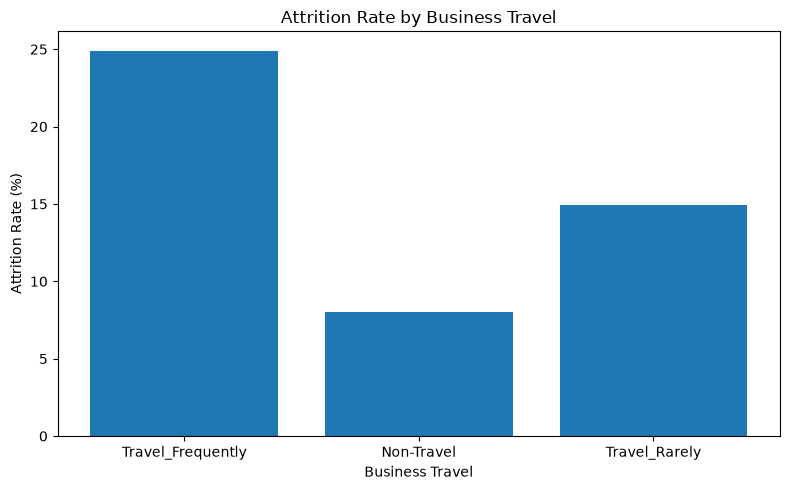

In [102]:
travel_pd = travel_summary.toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    travel_pd["BusinessTravel"],
    travel_pd["Attrition_Rate"]
)

plt.xlabel("Business Travel")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Business Travel")

plt.tight_layout()
plt.show()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


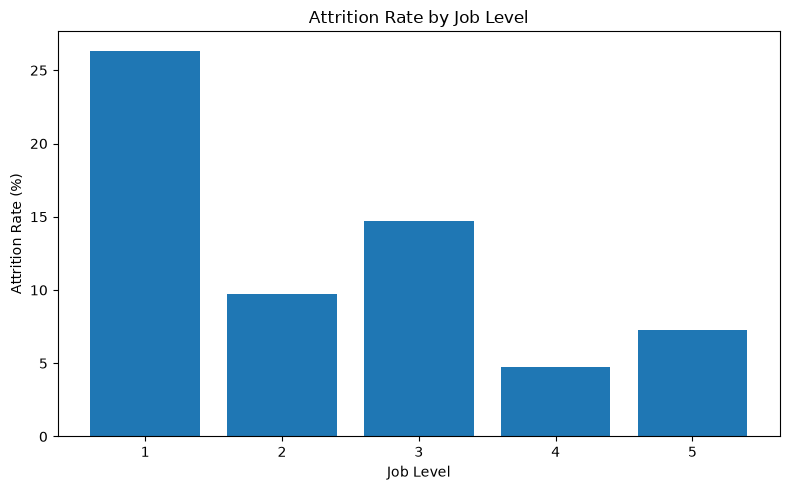

In [103]:
joblevel_pd = joblevel_summary.toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    joblevel_pd["JobLevel"],
    joblevel_pd["Attrition_Rate"]
)

plt.xlabel("Job Level")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Job Level")

plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


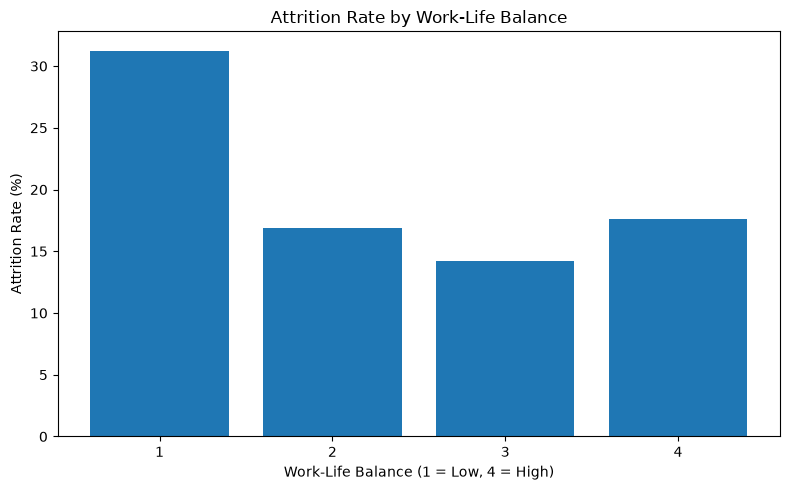

In [106]:
worklife_pd = worklife_summary.toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
worklife_pd["WorkLifeBalance"],
worklife_pd["Attrition_Rate"]
)

plt.xlabel("Work-Life Balance (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Work-Life Balance")

plt.xticks([1, 2, 3, 4])
plt.tight_layout()
plt.show()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


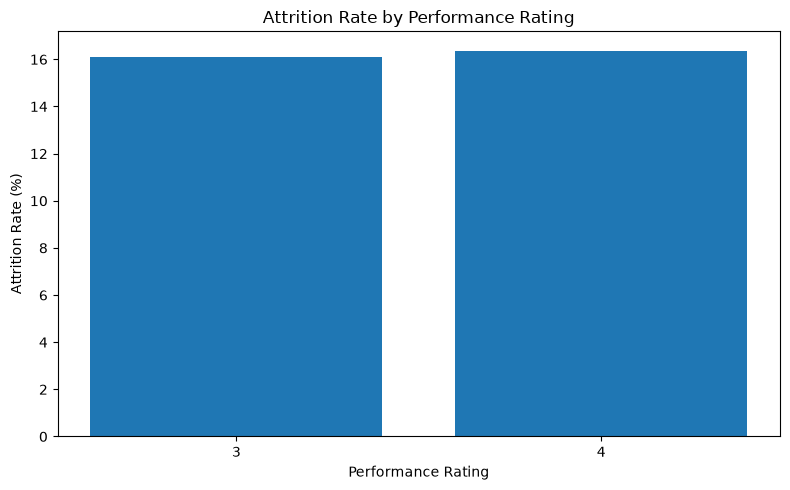

In [110]:
performance_pd = performance_summary.toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    performance_pd["PerformanceRating"],
    performance_pd["Attrition_Rate"]
)

plt.xlabel("Performance Rating")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Performance Rating")

plt.xticks([3, 4])
plt.tight_layout()
plt.show()

In [115]:
from pyspark.sql.functions import count, sum, round, col

department_level_summary = df_clean.groupBy(
    "Department", "JobLevel"
).agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

department_level_summary = department_level_summary.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

department_level_summary.show(truncate=False)

+----------------------+--------+---------------+--------------+--------------+
|Department            |JobLevel|Total_Employees|Employees_Left|Attrition_Rate|
+----------------------+--------+---------------+--------------+--------------+
|Human Resources       |3       |6              |2             |33.33         |
|Research & Development|1       |434            |101           |23.27         |
|Human Resources       |2       |13             |0             |0.0           |
|Sales                 |4       |34             |4             |11.76         |
|Sales                 |3       |83             |17            |20.48         |
|Human Resources       |4       |4              |0             |0.0           |
|Research & Development|5       |49             |3             |6.12          |
|Sales                 |5       |13             |2             |15.38         |
|Human Resources       |5       |7              |0             |0.0           |
|Sales                 |1       |76     

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


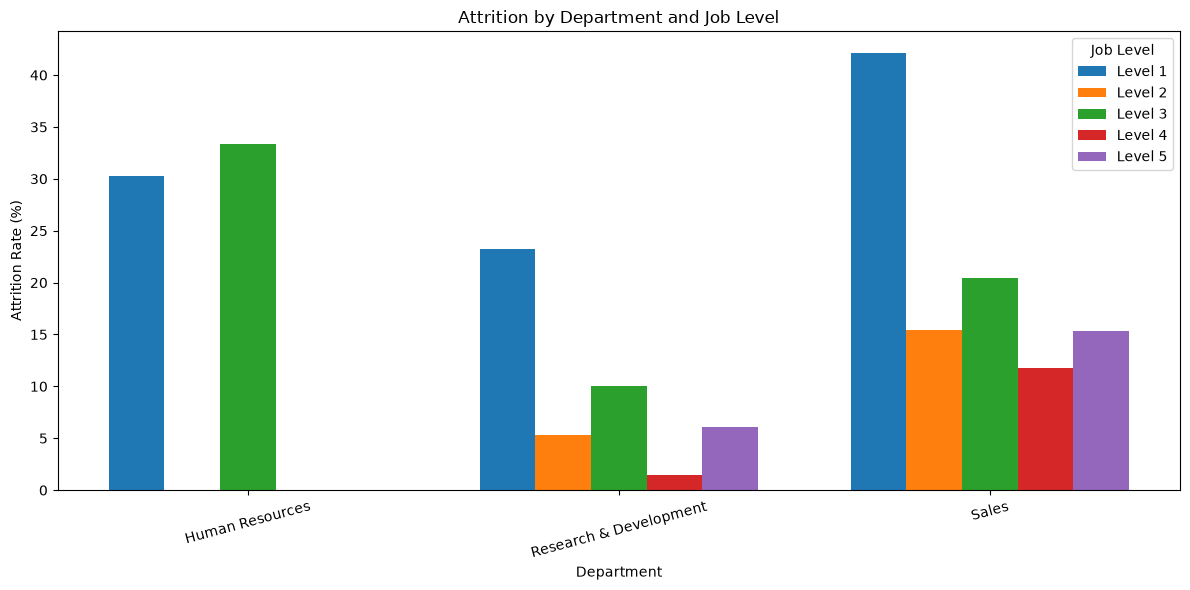

In [116]:
import matplotlib.pyplot as plt
import numpy as np

dept_level_pd = department_level_summary.toPandas()

departments = dept_level_pd["Department"].unique()
levels = sorted(dept_level_pd["JobLevel"].unique())

x = np.arange(len(departments))
width = 0.15

plt.figure(figsize=(12, 6))

for i, level in enumerate(levels):
    subset = (
        dept_level_pd[dept_level_pd["JobLevel"] == level]
        .set_index("Department")
        .reindex(departments)
    )

    plt.bar(
        x + (i - 2) * width,
        subset["Attrition_Rate"],
        width,
        label=f"Level {level}"
    )

plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition by Department and Job Level")
plt.xticks(x, departments, rotation=15)
plt.legend(title="Job Level")
plt.tight_layout()
plt.show()

/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/Users/srishtikashyap/Desktop/Pyspark-Practice/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/Users/srishtikashyap/Desktop/Pyspark-Practi

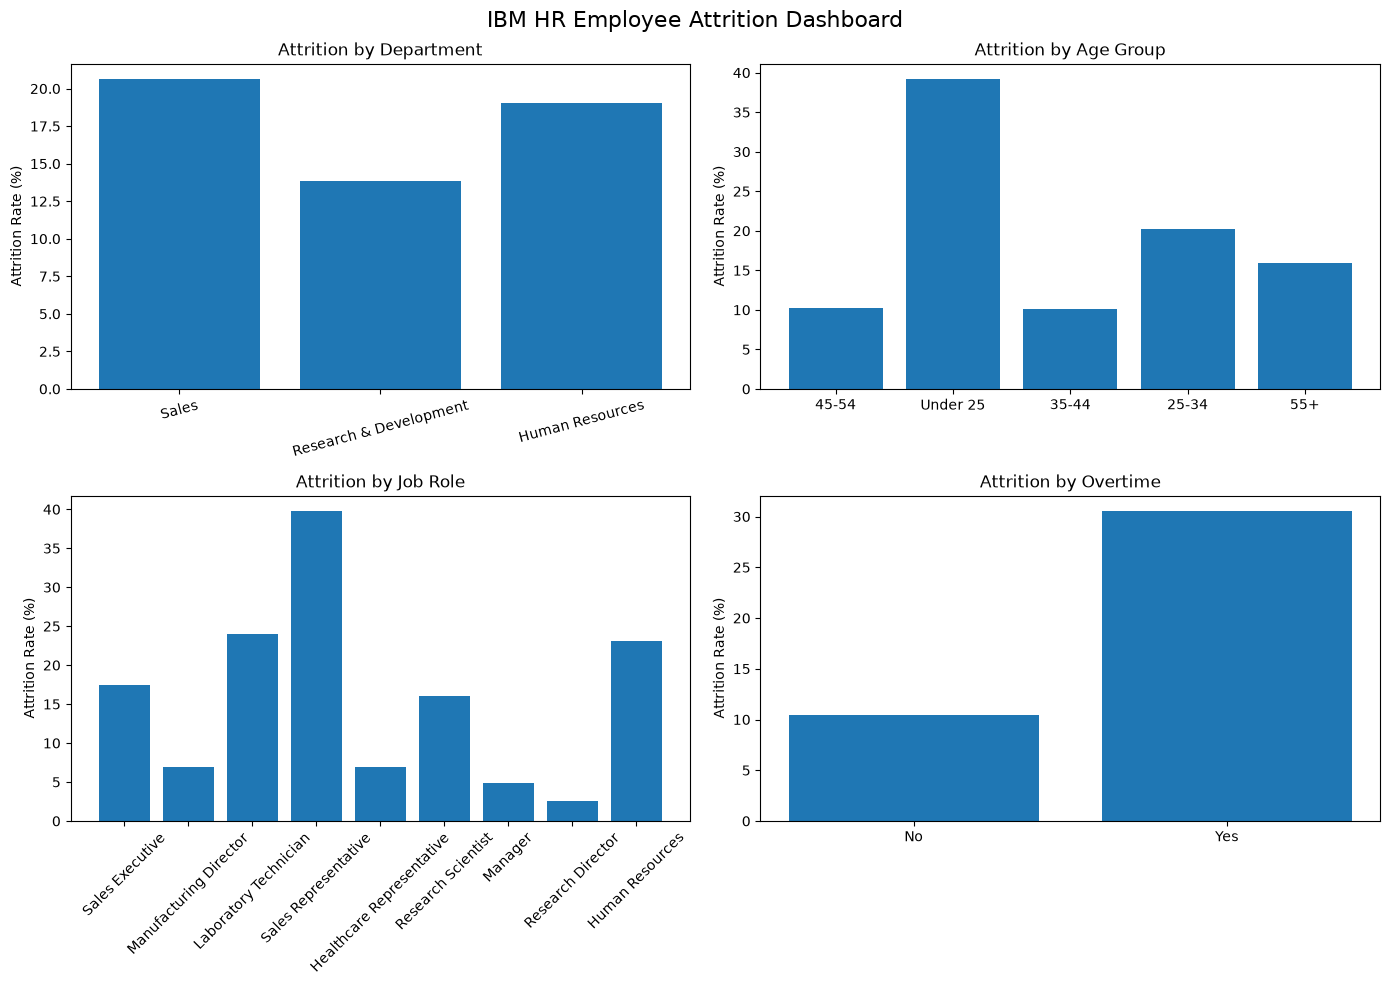

In [117]:
import matplotlib.pyplot as plt

# Convert PySpark summaries to Pandas
department_pd = department_summary.toPandas()
age_pd = age_summary.toPandas()
jobrole_pd = jobrole_summary.toPandas()
overtime_pd = overtime_summary.toPandas()

# Create a dashboard with 4 charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Department
axes[0, 0].bar(
    department_pd["Department"],
    department_pd["Attrition_Rate"]
)
axes[0, 0].set_title("Attrition by Department")
axes[0, 0].set_ylabel("Attrition Rate (%)")
axes[0, 0].tick_params(axis="x", rotation=15)

# Chart 2: Age group
axes[0, 1].bar(
    age_pd["Age_Group"],
    age_pd["Attrition_Rate"]
)
axes[0, 1].set_title("Attrition by Age Group")
axes[0, 1].set_ylabel("Attrition Rate (%)")

# Chart 3: Job role
axes[1, 0].bar(
    jobrole_pd["JobRole"],
    jobrole_pd["Attrition_Rate"]
)
axes[1, 0].set_title("Attrition by Job Role")
axes[1, 0].set_ylabel("Attrition Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=45)

# Chart 4: Overtime
axes[1, 1].bar(
    overtime_pd["OverTime"],
    overtime_pd["Attrition_Rate"]
)
axes[1, 1].set_title("Attrition by Overtime")
axes[1, 1].set_ylabel("Attrition Rate (%)")

# Main dashboard title
fig.suptitle("IBM HR Employee Attrition Dashboard", fontsize=16)

plt.tight_layout()
plt.show()

In [118]:
attrition_summary.show()

+---------------+--------------+--------------+
|Total_Employees|Employees_Left|Attrition_Rate|
+---------------+--------------+--------------+
|           1470|           237|         16.12|
+---------------+--------------+--------------+



In [119]:
from pyspark.sql.functions import col

employees_stayed = df_clean.filter(
    col("Attrition") == "No"
).count()

print("Employees who stayed:", employees_stayed)

Employees who stayed: 1233


In [120]:
total_employees = df_clean.count()

employees_stayed = df_clean.filter(
    col("Attrition") == "No"
).count()

stayed_percentage = (employees_stayed / total_employees) * 100

print(f"Percentage who stayed: {stayed_percentage:.2f}%")

Percentage who stayed: 83.88%


In [121]:
from pyspark.sql.functions import count, sum, col, round

department_analysis = df_clean.groupBy("Department").agg(
    count("*").alias("Total_Employees"),
    sum("Attrition_Flag").alias("Employees_Left")
)

department_analysis = department_analysis.withColumn(
    "Employees_Stayed",
    col("Total_Employees") - col("Employees_Left")
)

department_analysis = department_analysis.withColumn(
    "Attrition_Rate",
    round(
        col("Employees_Left") / col("Total_Employees") * 100,
        2
    )
)

department_analysis.show(truncate=False)

+----------------------+---------------+--------------+----------------+--------------+
|Department            |Total_Employees|Employees_Left|Employees_Stayed|Attrition_Rate|
+----------------------+---------------+--------------+----------------+--------------+
|Sales                 |446            |92            |354             |20.63         |
|Research & Development|961            |133           |828             |13.84         |
|Human Resources       |63             |12            |51              |19.05         |
+----------------------+---------------+--------------+----------------+--------------+



In [122]:
department_summary.orderBy(
    col("Attrition_Rate").desc()
).show(truncate=False)

+----------------------+---------------+--------------+--------------+
|Department            |Total_Employees|Employees_Left|Attrition_Rate|
+----------------------+---------------+--------------+--------------+
|Sales                 |446            |92            |20.63         |
|Human Resources       |63             |12            |19.05         |
|Research & Development|961            |133           |13.84         |
+----------------------+---------------+--------------+--------------+



## 2. Attrition by Department

The employee attrition analysis was performed across
the three departments: Sales, Human Resources, and
Research & Development.

The attrition rates were compared to identify
differences between departments.

The department with the highest attrition rate was
Sales, at 20.63%.

The department with the lowest attrition rate was
Research & Development at 13.84%.

In [124]:
jobrole_summary.orderBy(
    col("Attrition_Rate").desc()
).show(truncate=False)

+-------------------------+---------------+--------------+--------------+
|JobRole                  |Total_Employees|Employees_Left|Attrition_Rate|
+-------------------------+---------------+--------------+--------------+
|Sales Representative     |83             |33            |39.76         |
|Laboratory Technician    |259            |62            |23.94         |
|Human Resources          |52             |12            |23.08         |
|Sales Executive          |326            |57            |17.48         |
|Research Scientist       |292            |47            |16.1          |
|Manufacturing Director   |145            |10            |6.9           |
|Healthcare Representative|131            |9             |6.87          |
|Manager                  |102            |5             |4.9           |
|Research Director        |80             |2             |2.5           |
+-------------------------+---------------+--------------+--------------+



## 3. Attrition by Job Role

Employee attrition was analyzed across different
job roles to identify differences in attrition rates.

The results show that attrition rates vary across
job roles.

The job role with the highest attrition rate was
Sales Representative , at 39.76%.

The job role with the lowest attrition rate was
Research Director, at 2.5%.

These results help identify job roles where
employee attrition may require further investigation.